In [ ]:
import marimo as mo

# Análisis exploratorio: ubicaciones mencionadas en los avisos

`ubicaciones_aviso.csv` tiene una fila por lugar que nombra una publicación de Agua de
Hermosillo: una colonia ("colonia Casa Linda", o el nombre suelto en la tabla de un
volante) o un cruce de calles ("José Obregón y Rosales"), que se geocodifica con los ejes
del Marco Geoestadístico. Cada fila dice cómo se resolvió (`match_method`) y de dónde salió
(`source_field`: texto, OCR o ambos). Es el puente entre las publicaciones y el mapa.

Casi todas sus columnas son categóricas. Para las secciones que piden variables numéricas
(anomalías multivariadas, correlación y reducción de dimensión) se construyen dos tablas
derivadas: los cruces geocodificados con su distancia al centroide de la colonia asignada,
y la "huella" territorial de cada publicación (cuántos lugares nombra, qué tan dispersos
están y cómo se resolvieron).

## Objetivos

1. Auto EDA con ydata-profiling, publicado en `docs/eda/`.
2. Datos faltantes y su mecanismo.
3. Anomalías con regla de Tukey y PyOD (IForest, ECOD y LOF).
4. Relaciones entre variables por visualización.
5. Correlación entre variables categóricas y numéricas.
6. Reducción a 2D con PCA, t-SNE y UMAP.
7. Preguntas para los usuarios.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from project_name.eda import (
    CATEGORICAL,
    NEUTRAL,
    agreement_table,
    cramers_v_matrix,
    embed_2d,
    embedding_quality,
    iqr_outliers,
    missing_table,
    plot_embeddings,
    plot_heatmap,
    processed_path,
    pyod_outliers,
    run_ydata_profile,
    ydata_summary,
)

DATASET = "ubicaciones_aviso"
pd.set_option("display.max_rows", 60)

## 1. Auto EDA con ydata-profiling

Reporte completo:
[`docs/eda/ubicaciones_aviso.html`](../../docs/eda/ubicaciones_aviso.html), generado por
`scripts/ydata_profile.py` en su propio entorno (ydata-profiling 4.18 exige pandas<3).

In [ ]:
report_html = run_ydata_profile(DATASET)
ydata_overview, ydata_alerts = ydata_summary(DATASET)
ydata_overview.to_frame("valor")

,valor
filas,16261
columnas,8
celdas faltantes,29971
% celdas faltantes,23.04
columnas con faltantes,3
filas duplicadas,0
memoria (MB),6.27
tipo Numeric,4
tipo Categorical,3
tipo Text,1


In [ ]:
ydata_alerts

,columna,alerta,detalle
0,lat,alta correlación,is highly overall correlated with [location_type] and 1 other fields
1,location_type,alta correlación,is highly overall correlated with [lat] and 2 other fields
2,lon,alta correlación,is highly overall correlated with [location_type] and 1 other fields
3,match_method,alta correlación,is highly overall correlated with [lat] and 2 other fields
4,post_id,alta correlación,is highly overall correlated with [source_field]
5,source_field,alta correlación,is highly overall correlated with [post_id]
6,colonia_id,faltantes,383 (2.4%) missing values
7,lat,faltantes,14794 (91.0%) missing values
8,lon,faltantes,14794 (91.0%) missing values


El reporte marca 23% de celdas faltantes, casi todas en `lat` y `lon` (91%), y una
asociación fuerte entre `lat`, `lon`, `location_type` y `match_method`. Las dos alertas
son la misma: solo los cruces geocodificados tienen coordenadas. La asociación entre
`post_id` y `source_field` es un artefacto de tratar el identificador como categoría.

## 2. Datos faltantes

In [ ]:
locations = pd.read_csv(processed_path(DATASET), dtype={"post_id": str, "colonia_id": str})
posts = pd.read_csv(
    processed_path("publicaciones_aguah"),
    dtype={"post_id": str},
    parse_dates=["published_at"],
    usecols=[
        "post_id",
        "published_at",
        "year",
        "event_type",
        "has_image",
        "reactions_total",
        "reactions_angry",
        "angry_share",
        "comments_count",
    ],
)
colonias = pd.read_csv(
    processed_path("colonias_hermosillo"),
    dtype={"colonia_id": str, "locality_code": str},
    usecols=[
        "colonia_id",
        "settlement_name",
        "locality_code",
        "area_km2",
        "centroid_lat",
        "centroid_lon",
    ],
)
# Cada mención con los datos de su publicación; todas las publicaciones existen.
mentions = locations.merge(posts, on="post_id", how="left", validate="many_to_one")
print(f"menciones sin publicación: {mentions['published_at'].isna().sum()}")
locations.shape

menciones sin publicación: 0


In [ ]:
missing_table(locations)

,nulos,vacios,% nulos,% vacios
lat,14794,0,90.98,0.0
lon,14794,0,90.98,0.0
colonia_id,383,0,2.36,0.0


In [ ]:
pd.crosstab(
    locations["match_method"],
    [
        locations["lat"].isna().map({True: "sin coordenadas", False: "con coordenadas"}),
        locations["colonia_id"].isna().map({True: "sin colonia", False: "con colonia"}),
    ],
)

lat con coordenadas sin coordenadas colonia_id con colonia con colonia sin colonia match_method colonia_con_marcador 0 2380 0 colonia_en_catalogo 0 12031 0 cruce_geocodificado 1467 0 0 unmatched 0 0 383

Los dos faltantes los determina `match_method` sin excepción:

- `lat` y `lon` solo existen en `cruce_geocodificado` (1,467 filas). Una mención de colonia
  no tiene un punto, tiene un polígono que ya está en `colonias_hermosillo`. Faltante
  estructural: no se imputa. Para mapear una mención de colonia se usa el centroide o el
  polígono de la colonia.
- `colonia_id` falta exactamente en las 383 filas `unmatched` (2.4%): cruces que no se
  pudieron geocodificar. Es el faltante real del dataset. Se conservan para medir la
  cobertura y se excluyen de los conteos por colonia.

¿El `unmatched` depende de algo observable (MAR) o es aleatorio (MCAR)?

In [ ]:
_crosses = mentions[mentions["location_type"] == "cruce"].assign(
    unmatched=lambda frame: frame["match_method"] == "unmatched"
)
pd.concat(
    {
        "por fuente": _crosses.groupby("source_field")["unmatched"].agg(["mean", "size"]),
        "por año": _crosses.groupby("year")["unmatched"].agg(["mean", "size"]),
        "por tipo de evento": _crosses.groupby("event_type")["unmatched"].agg(
            ["mean", "size"]
        ),
    }
).rename(columns={"mean": "% de cruces sin resolver", "size": "cruces"}).assign(
    **{
        "% de cruces sin resolver": lambda frame: (
            100 * frame["% de cruces sin resolver"]
        ).round(1)
    }
)

% de cruces sin resolver cruces por fuente ocr 32.9 158 texto 19.6 1692 por año 2020 5.6 18 2021 13.4 232 2022 17.4 178 2023 20.3 118 2024 25.5 243 2025 20.8 737 2026 25.0 324 por tipo de evento corte_programado 18.8 64 emergencia 16.5 310 otro 21.1 1407 pipas 28.6 28 restablecimiento 36.6 41

In [ ]:
locations.loc[locations["match_method"] == "unmatched", "raw_text"].value_counts().head(12)

,count
raw_text,
Real y sector aledaño,5
Yécora y Gral,4
Peña Colorada entre Blvd,4
Real y zona aledaña,4
Dos entre Av,4
Dos entre Ave,4
Luis Encinas y Ave,3
Misión de Bac y Misiones Sur,3
Musaro y Ave,3


Uno de cada cinco cruces queda sin resolver (383 de 1,850), y la tasa depende de cosas
observables: 33% en el OCR frente a 20% en el texto, de 6% en 2020 a 25% en 2024 y 2026,
37% en restablecimientos. El faltante es MAR. Los textos sin resolver muestran por qué: el
cruce se cortó en la extracción ("Yécora y Gral", "Dos entre Av", "Musaro y Ave") o no es
un cruce ("Real y sector aledaño"). La mejora está en la extracción del proyecto 1, no en
imputar.

### Menciones repetidas

Un aviso puede nombrar la misma colonia dos veces: por su nombre y por un cruce que cae en
ella, o en el texto y en el volante.

In [ ]:
_resolved = locations.dropna(subset=["colonia_id"])
_repeated = _resolved[_resolved.duplicated(["post_id", "colonia_id"], keep=False)]
pd.Series(
    {
        "filas idénticas (post_id, location_type, raw_text)": int(
            locations.duplicated(["post_id", "location_type", "raw_text"]).sum()
        ),
        "filas que repiten (post_id, colonia_id)": int(
            _resolved.duplicated(["post_id", "colonia_id"]).sum()
        ),
        "publicaciones con alguna colonia repetida": _repeated["post_id"].nunique(),
        "pares (post_id, colonia_id) distintos": len(
            _resolved.drop_duplicates(["post_id", "colonia_id"])
        ),
    },
    name="filas",
).to_frame()

,filas
"filas idénticas (post_id, location_type, raw_text)",0
"filas que repiten (post_id, colonia_id)",758
publicaciones con alguna colonia repetida,751
"pares (post_id, colonia_id) distintos",15120


No hay filas duplicadas, pero 758 filas repiten una colonia ya nombrada en el mismo aviso
con otro texto. Para contar publicaciones por colonia hay que deduplicar por
`(post_id, colonia_id)`; contar filas inflaría las colonias que aparecen por nombre y por
cruce a la vez.

## 3. Anomalías

Dos tipos de anomalía con sentido en esta tabla:

1. Publicaciones que nombran muchísimos lugares (volantes con tablas de colonias).
   Técnica univariada: Tukey sobre el logaritmo del número de menciones por publicación.
2. Cruces mal geocodificados: un punto lejos de la colonia que se le asignó, o lejos del
   resto de la ciudad. Técnicas: Tukey sobre la distancia al centroide de la colonia
   relativa a su tamaño, y PyOD (IForest, ECOD y LOF) sobre latitud, longitud y esa
   distancia.

In [ ]:
mentions_per_post = mentions.groupby("post_id").size().rename("n_mentions")
_flags = iqr_outliers(np.log(mentions_per_post))
print(
    f"{len(mentions_per_post)} publicaciones con ubicaciones; mediana "
    f"{mentions_per_post.median():.0f} menciones, máximo {mentions_per_post.max()}; "
    f"Tukey(log) marca {_flags.sum()} (desde {mentions_per_post[_flags].min()} menciones)"
)

3788 publicaciones con ubicaciones; mediana 2 menciones, máximo 91; Tukey(log) marca 57 (desde 32 menciones)


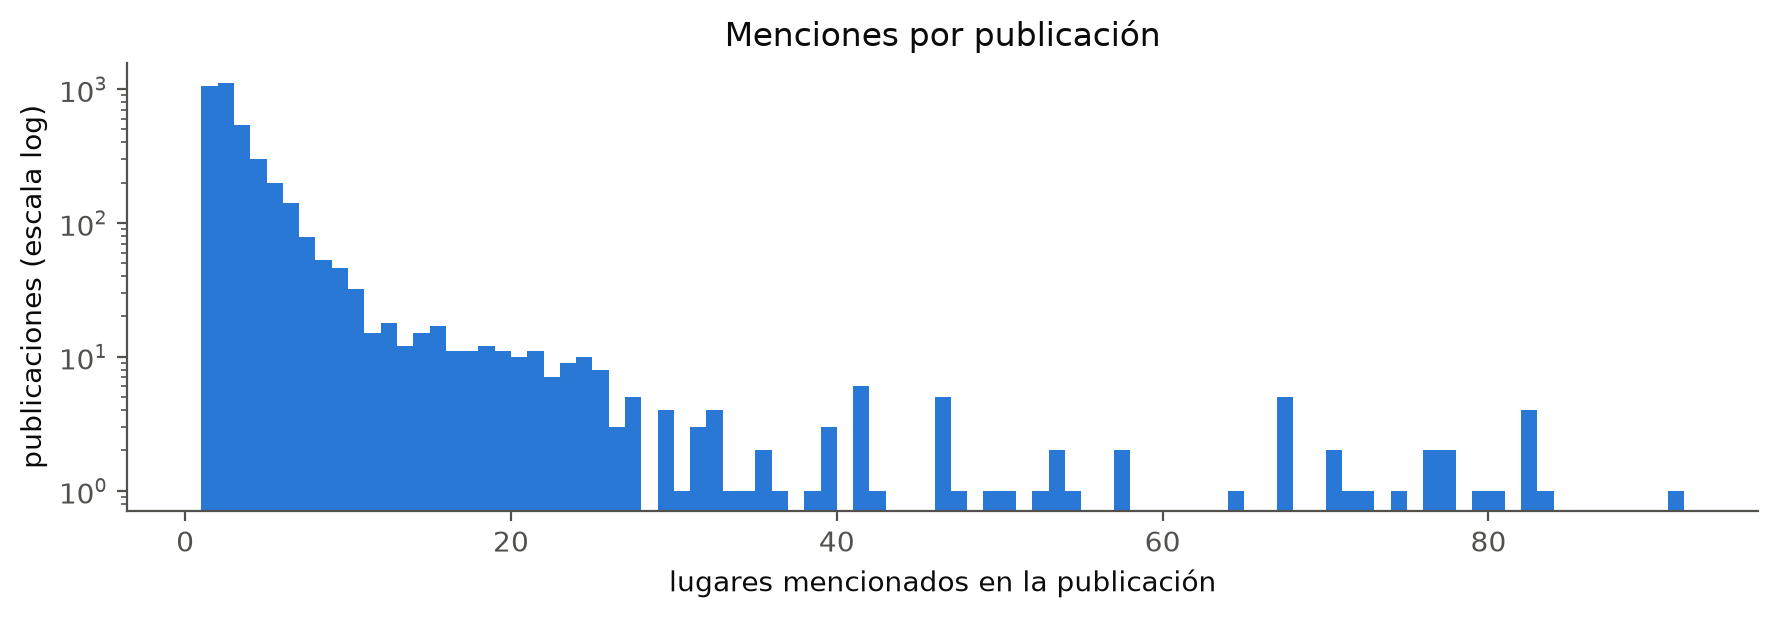

In [ ]:
_fig, _ax = plt.subplots(figsize=(9, 3.2))
_ax.hist(mentions_per_post, bins=range(1, mentions_per_post.max() + 2), color="#2a78d6")
_ax.set_yscale("log")
_ax.set_xlabel("lugares mencionados en la publicación")
_ax.set_ylabel("publicaciones (escala log)")
_ax.set_title("Menciones por publicación")
_ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

In [ ]:
_top = mentions_per_post.nlargest(10)
_sources = mentions.groupby("post_id")["source_field"].agg(lambda s: s.value_counts().idxmax())
posts.set_index("post_id").loc[_top.index, ["published_at", "event_type", "has_image"]].assign(
    n_mentions=_top, main_source=_sources.loc[_top.index]
)

,published_at,event_type,has_image,n_mentions,main_source
post_id,,,,,
5434626143233152,2022-01-26 18:10:16,corte_programado,True,91,ambos
761804322658508,2023-12-13 17:17:46,emergencia,True,83,ocr
442742857897991,2022-08-20 09:22:19,emergencia,True,82,ocr
709455041226770,2023-09-16 09:03:05,corte_programado,True,82,ocr
748881327284141,2023-11-21 07:42:37,emergencia,True,82,ocr
807295351442738,2024-02-24 10:45:40,corte_programado,True,82,ocr
667038732135068,2023-07-04 07:38:39,otro,True,80,ocr
557339319771677,2023-01-17 11:13:06,restablecimiento,True,79,ocr
1101847495320854,2025-04-16 08:56:43,emergencia,True,77,ocr


Tukey marca 57 publicaciones, las que nombran 32 lugares o más. Las de 79 a 91 lugares son
volantes (todas traen imagen) de cortes, emergencias y restablecimientos que listan las
colonias afectadas; sus menciones salen sobre todo del OCR.
No son errores, pero cada una pesa en el conteo por colonia igual que un aviso de una
sola calle: para el tablero conviene ponderar por `1 / n_mentions` o mostrar aparte los
avisos masivos.

In [ ]:
# Distancia (km) de cada cruce geocodificado al centroide de su colonia, y esa distancia
# dividida entre la raíz del área (el "radio" de la colonia), para comparar colonias de
# tamaños distintos.
geocoded = locations[locations["match_method"] == "cruce_geocodificado"].merge(
    colonias, on="colonia_id", how="left", validate="many_to_one"
)
_lat1, _lon1, _lat2, _lon2 = map(
    np.radians,
    [geocoded["lat"], geocoded["lon"], geocoded["centroid_lat"], geocoded["centroid_lon"]],
)
_haversine = (
    np.sin((_lat2 - _lat1) / 2) ** 2
    + np.cos(_lat1) * np.cos(_lat2) * np.sin((_lon2 - _lon1) / 2) ** 2
)
geocoded["distance_km"] = 2 * 6371 * np.arcsin(np.sqrt(_haversine))
geocoded["distance_relative"] = geocoded["distance_km"] / np.sqrt(geocoded["area_km2"])
geocoded[["distance_km", "distance_relative"]].describe().round(3)

,distance_km,distance_relative
count,1467.000,1467.000
mean,0.318,0.486
std,0.256,0.266
min,0.005,0.005
25%,0.146,0.295
50%,0.256,0.458
75%,0.425,0.630
max,2.545,1.857


In [ ]:
_features = geocoded[["lat", "lon", "distance_km"]]
geocoded_outliers = pyod_outliers(
    pd.DataFrame(StandardScaler().fit_transform(_features), columns=_features.columns),
    contamination=0.02,
).assign(tukey_relative=iqr_outliers(geocoded["distance_relative"]))
agreement_table(geocoded_outliers.filter(regex="_outlier|tukey"))

,iforest_outlier,ecod_outlier,lof_outlier,tukey_relative
iforest_outlier,1.00,0.43,0.05,0.06
ecod_outlier,0.43,1.00,0.04,0.06
lof_outlier,0.05,0.04,1.00,0.06
tukey_relative,0.06,0.06,0.06,1.00


In [ ]:
geocoded_outliers.filter(regex="_outlier|tukey").sum().rename("marcados").to_frame()

,marcados
iforest_outlier,30
ecod_outlier,30
lof_outlier,29
tukey_relative,40


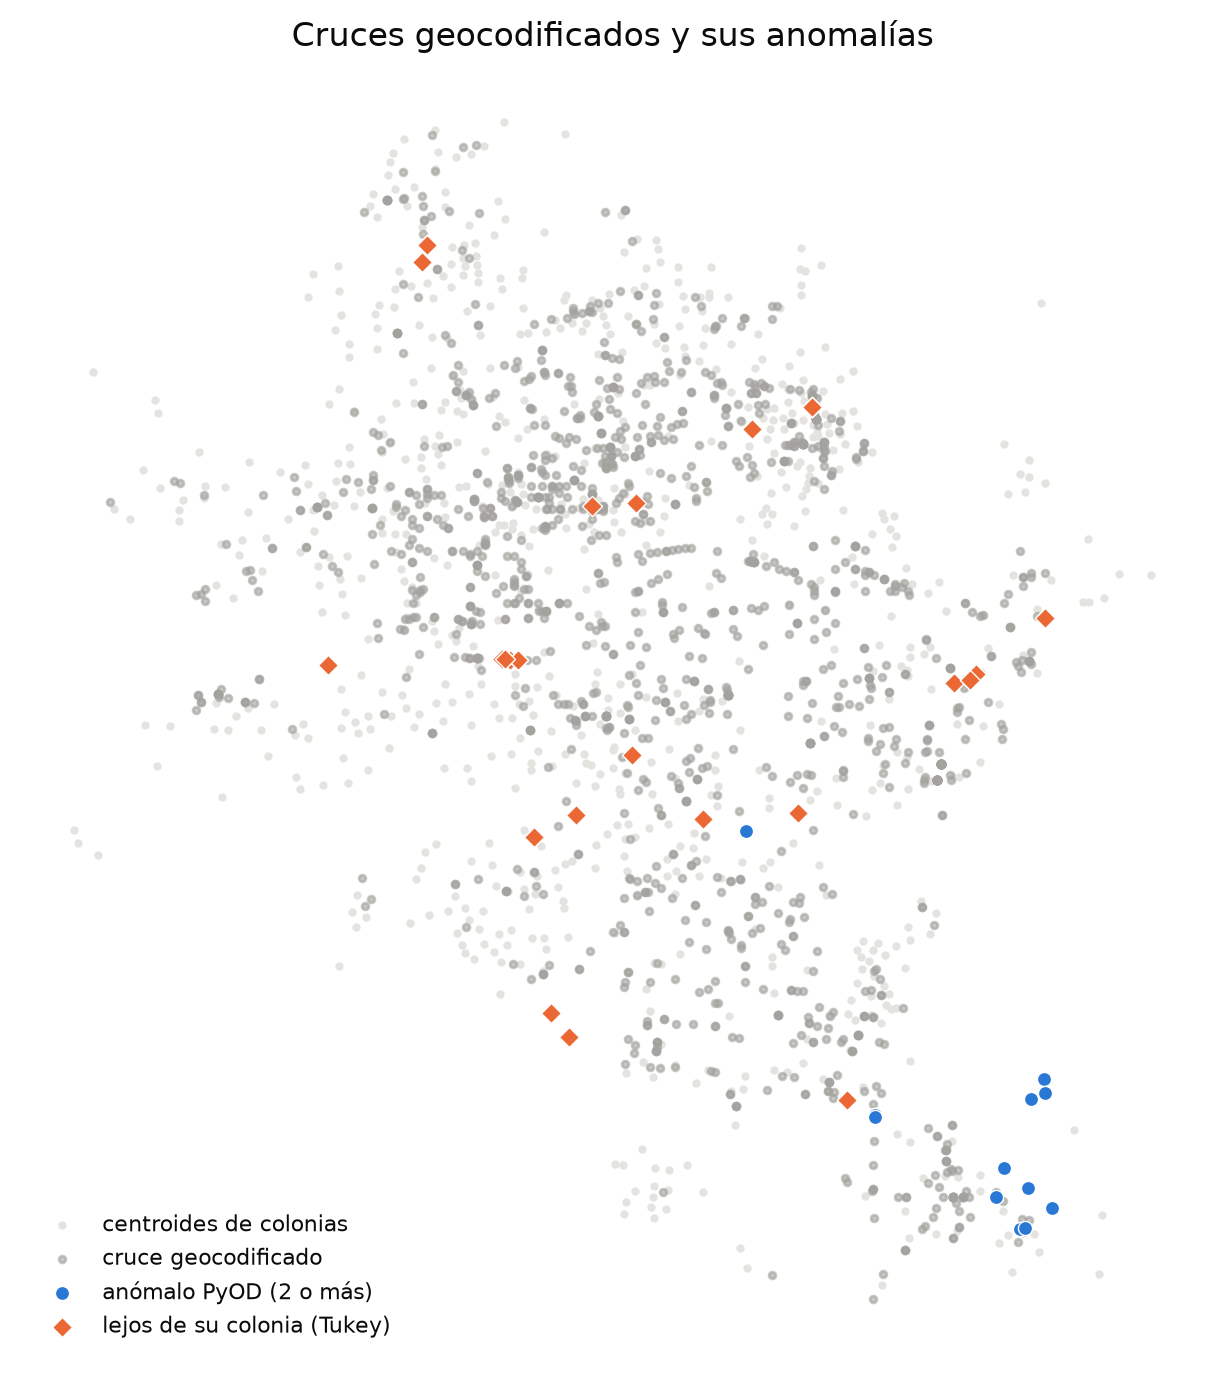

In [ ]:
_city = colonias[colonias["locality_code"] == "0001"]
_pyod = geocoded_outliers["votes"] >= 2
_tukey = geocoded_outliers["tukey_relative"]
_fig, _ax = plt.subplots(figsize=(7.5, 7))
_ax.scatter(
    _city["centroid_lon"],
    _city["centroid_lat"],
    s=4,
    color="#e4e3df",
    label="centroides de colonias",
)
_ax.scatter(
    geocoded.loc[~_pyod & ~_tukey, "lon"],
    geocoded.loc[~_pyod & ~_tukey, "lat"],
    s=6,
    color=NEUTRAL,
    alpha=0.6,
    label="cruce geocodificado",
)
_ax.scatter(
    geocoded.loc[_pyod, "lon"],
    geocoded.loc[_pyod, "lat"],
    s=26,
    color=CATEGORICAL[0],
    edgecolors="white",
    linewidths=0.5,
    label="anómalo PyOD (2 o más)",
)
_ax.scatter(
    geocoded.loc[_tukey, "lon"],
    geocoded.loc[_tukey, "lat"],
    s=26,
    marker="D",
    color=CATEGORICAL[1],
    edgecolors="white",
    linewidths=0.5,
    label="lejos de su colonia (Tukey)",
)
_ax.set_aspect("equal")
_ax.set_xticks([])
_ax.set_yticks([])
_ax.spines[:].set_visible(False)
_ax.legend(frameon=False, loc="lower left", fontsize=8)
_ax.set_title("Cruces geocodificados y sus anomalías")
_fig.tight_layout()
_fig

In [ ]:
geocoded.loc[
    geocoded_outliers["tukey_relative"],
    ["raw_text", "settlement_name", "area_km2", "distance_km", "distance_relative"],
].sort_values("distance_relative", ascending=False).round(3).head(12)

,raw_text,settlement_name,area_km2,distance_km,distance_relative
987,Pueblo Nuevo y Blvd. Agustín F,San Germán,0.032,0.330,1.857
992,Pueblo Nuevo y Agustín Zamora,San Germán,0.032,0.330,1.857
988,Pueblo Nuevo y Blvd. Agustín F,San Germán,0.032,0.330,1.857
1327,Solidaridad y Paseo Río Sonora,Proyecto Río Sonora,2.879,2.545,1.500
1134,Isabel La Católica y Margarita Maza de Juárez,H Ayuntamiento,0.018,0.200,1.469
561,Rosario Ibarra de Piedra y Enrique Mazón,Ferrocarrilera,0.513,1.036,1.447
1123,A entre J y K,Las Minitas,0.298,0.767,1.404
1252,Solidaridad y Blvr. Hidalgo,Palmar del Sol,0.054,0.323,1.392
1299,Rosales y Blvr. Serna,El Malecón,0.112,0.463,1.380
1298,Rosales y bulevar Serna,El Malecón,0.112,0.463,1.380


- Ningún cruce cae fuera de Hermosillo: el más lejano está a 2.5 km del centroide de su
  colonia. La geocodificación no tiene errores groseros.
- IForest y ECOD coinciden en 43% de sus marcas; LOF y Tukey casi no coinciden con nadie
  (4% a 6%): miden cosas distintas.
- Los marcados por al menos dos detectores de PyOD están casi todos en el extremo sureste
  de la ciudad, donde hay pocos cruces y quedan aislados. Son puntos legítimos en colonias
  periféricas.
- Tukey sobre la distancia relativa (40 cruces) encuentra lo más útil: cruces que caen a
  más de 1.2 "radios" de su colonia. Los mayores son cruces sobre bulevares o avenidas que
  bordean colonias pequeñas ("Pueblo Nuevo y Blvd. Agustín F" asignado a San Germán,
  "Solidaridad y Blvr. Hidalgo" a Palmar del Sol), donde el punto queda en la orilla o en
  la colonia de enfrente. La asignación a la "colonia más cercana" es ambigua justo en los
  bulevares.

## 4. Relaciones entre variables por visualización

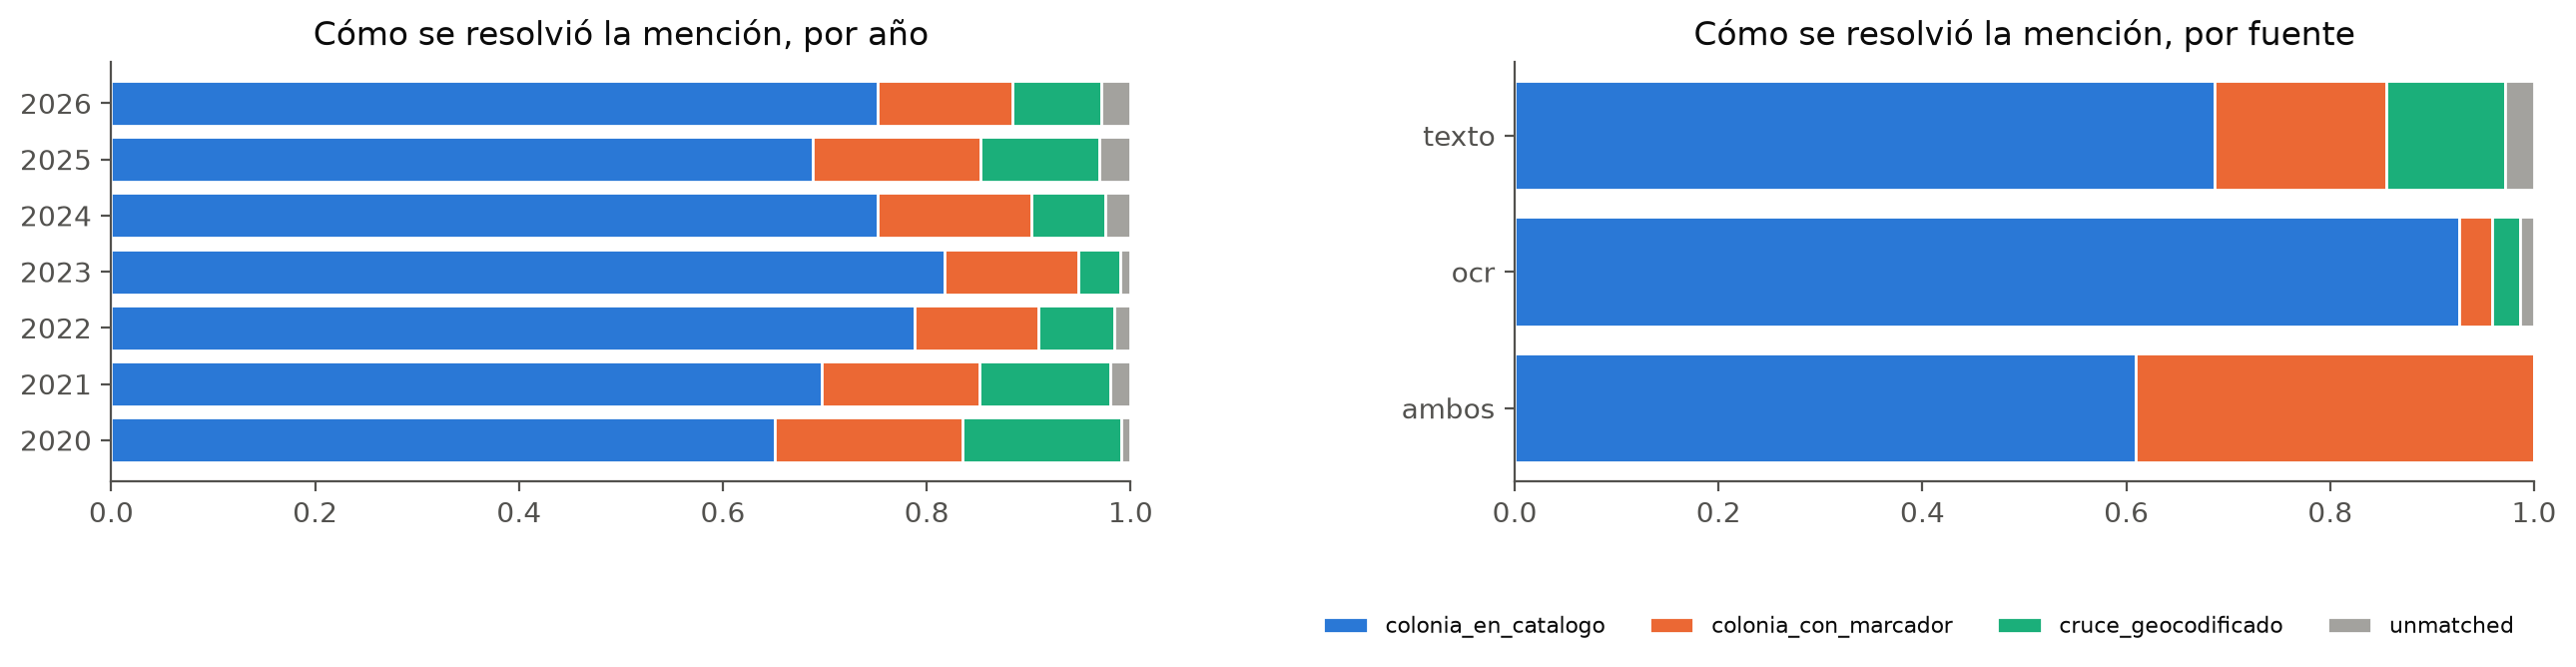

In [ ]:
_methods = ["colonia_en_catalogo", "colonia_con_marcador", "cruce_geocodificado", "unmatched"]
_colors = [CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[2], NEUTRAL]
_by_year = pd.crosstab(mentions["year"], mentions["match_method"], normalize="index")[_methods]
_by_source = pd.crosstab(
    mentions["source_field"], mentions["match_method"], normalize="index"
)[_methods]
_fig, _axes = plt.subplots(1, 2, figsize=(13, 3.8))
for _ax, _table, _title in [
    (_axes[0], _by_year, "por año"),
    (_axes[1], _by_source, "por fuente"),
]:
    _left = 0
    for _method, _color in zip(_methods, _colors):
        _ax.barh(
            _table.index.astype(str),
            _table[_method],
            left=_left,
            color=_color,
            edgecolor="white",
            linewidth=1,
            label=_method,
        )
        _left = _left + _table[_method]
    _ax.set_xlim(0, 1)
    _ax.set_title(f"Cómo se resolvió la mención, {_title}")
    _ax.spines[["top", "right"]].set_visible(False)
_axes[1].legend(
    frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, -0.42), ncol=4
)
_fig.tight_layout()
_fig

In [ ]:
pd.crosstab(mentions["event_type"], mentions["source_field"], normalize="index").mul(
    100
).round(1).join(mentions["event_type"].value_counts().rename("menciones"))

,ambos,ocr,texto,menciones
event_type,,,,
corte_programado,10.7,60.1,29.3,1753
emergencia,2.5,25.7,71.8,2829
otro,4.4,17.4,78.2,10944
pipas,17.9,35.7,46.4,84
restablecimiento,1.8,22.9,75.3,651


In [ ]:
_with_location = posts["post_id"].isin(locations["post_id"])
pd.DataFrame(
    {
        "% con al menos una ubicación": posts.assign(has_location=_with_location)
        .groupby("event_type")["has_location"]
        .mean()
        .mul(100)
        .round(1),
        "publicaciones": posts["event_type"].value_counts(),
    }
)

,% con al menos una ubicación,publicaciones
event_type,,
corte_programado,93.9,295
emergencia,76.3,811
otro,70.3,3919
pipas,90.2,41
restablecimiento,75.4,134


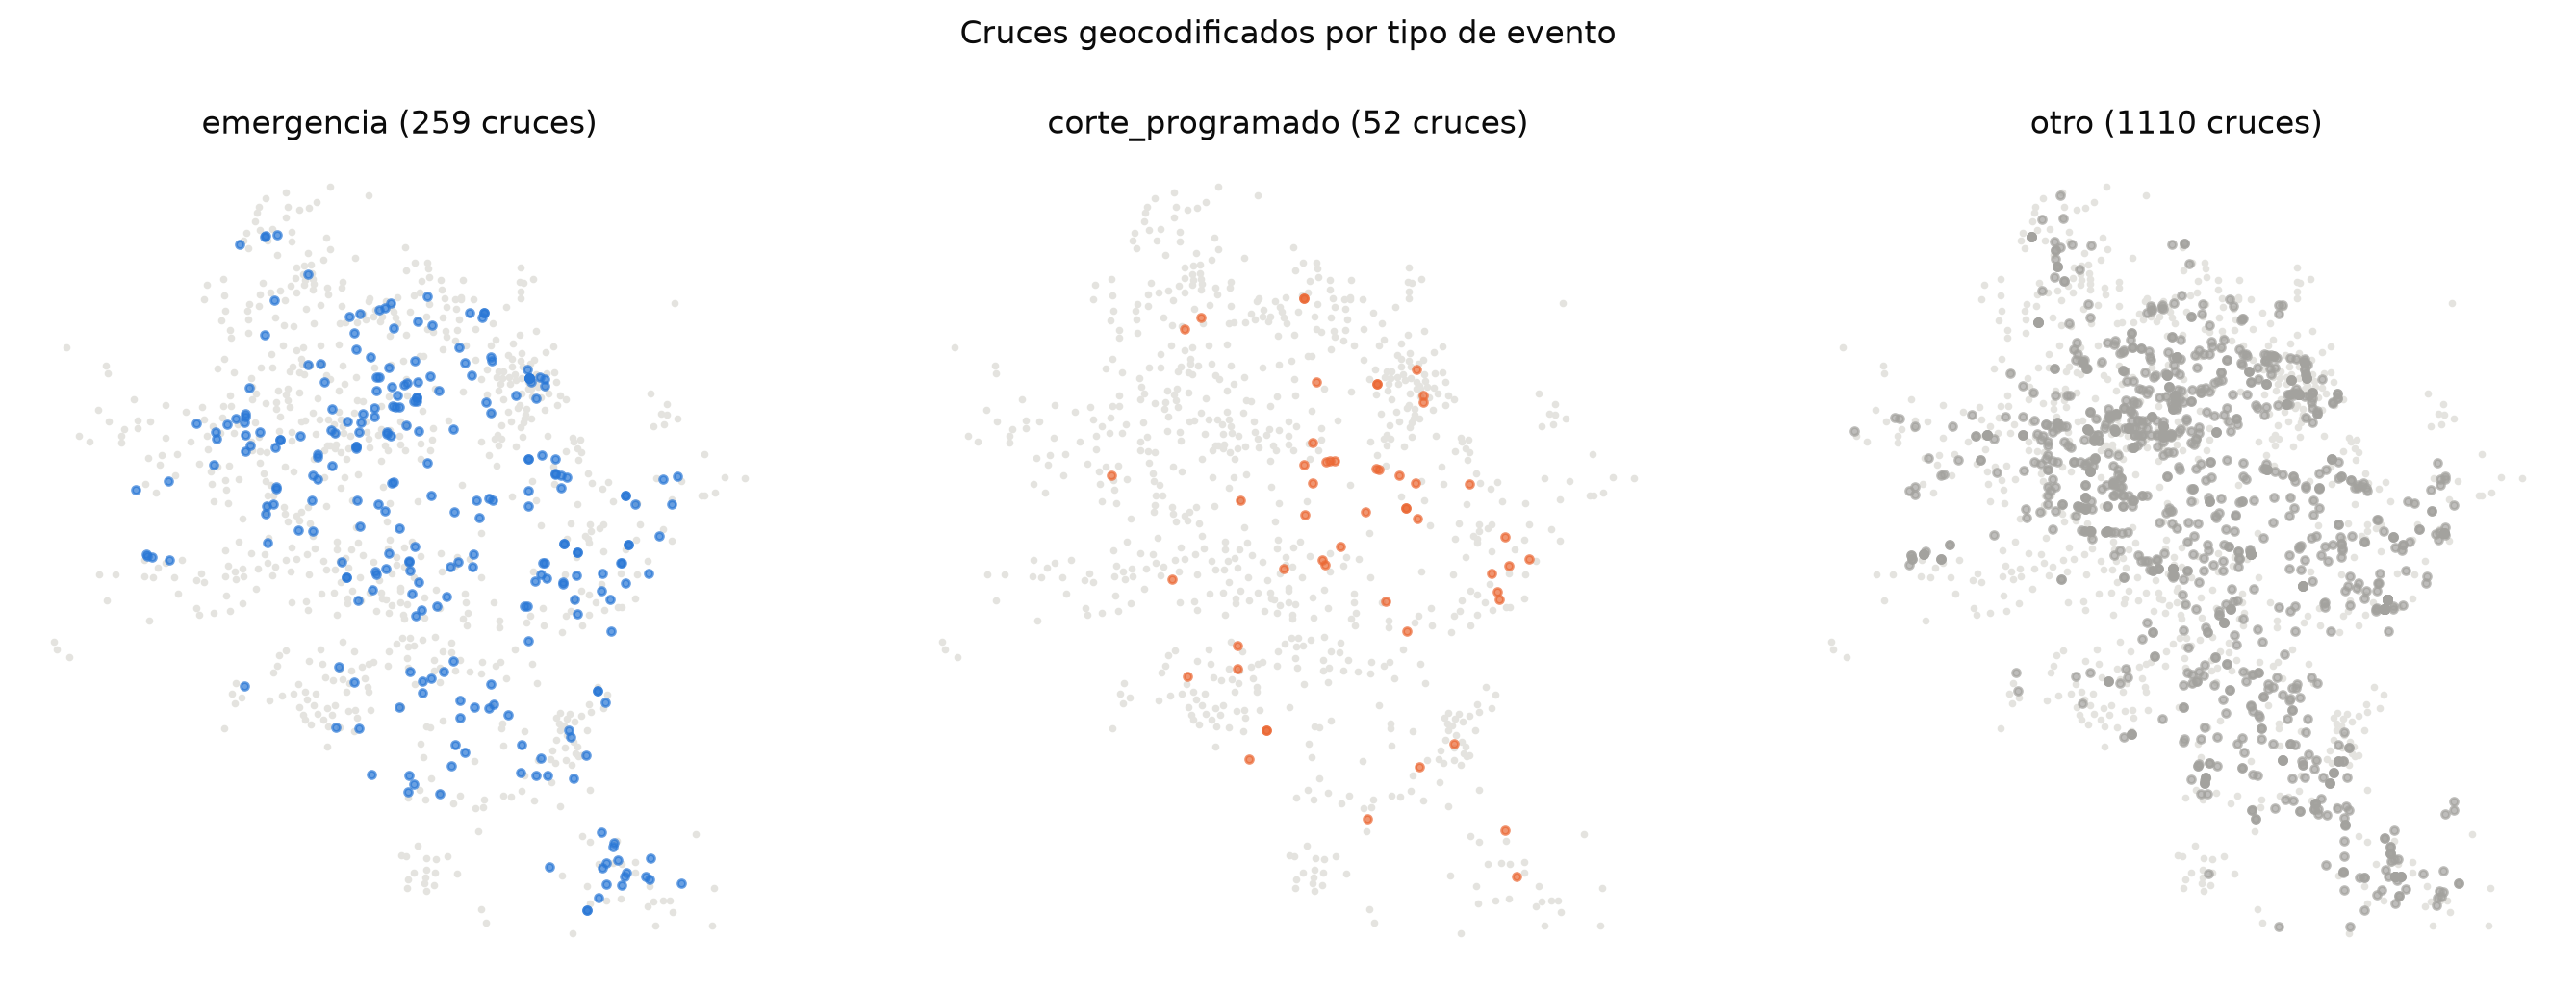

In [ ]:
_events = mentions.drop_duplicates("post_id").set_index("post_id")["event_type"]
_points = geocoded.assign(event_type=geocoded["post_id"].map(_events))
_city = colonias[colonias["locality_code"] == "0001"]
_palette = {"emergencia": CATEGORICAL[0], "corte_programado": CATEGORICAL[1]}
_fig, _axes = plt.subplots(1, 3, figsize=(14, 5.2), sharex=True, sharey=True)
for _ax, _event in zip(_axes, ["emergencia", "corte_programado", "otro"]):
    _ax.scatter(_city["centroid_lon"], _city["centroid_lat"], s=3, color="#e4e3df")
    _subset = _points[_points["event_type"] == _event]
    _ax.scatter(
        _subset["lon"], _subset["lat"], s=8, color=_palette.get(_event, NEUTRAL), alpha=0.7
    )
    _ax.set_title(f"{_event} ({len(_subset)} cruces)")
    _ax.set_aspect("equal")
    _ax.set_xticks([])
    _ax.set_yticks([])
    _ax.spines[:].set_visible(False)
_fig.suptitle("Cruces geocodificados por tipo de evento")
_fig.tight_layout(rect=(0, 0, 1, 0.94))
_fig

- El nombre suelto (`colonia_en_catalogo`) es el método dominante todos los años (65% a
  82%) y en el OCR es casi lo único (93%): los volantes traen tablas de colonias sin la
  palabra "colonia". Es también el método menos seguro.
- Los cruces salen sobre todo del texto de la publicación; en el OCR son 3%.
- Las menciones de `ambos` (texto y volante) son las de mayor confianza: 39% con marcador
  explícito y ningún cruce.
- `corte_programado` es el tipo con más publicaciones con ubicación (94%); "otro" el que
  menos (70%), pero aun así la mayoría de las publicaciones "otro" nombra algún lugar.
- Los cruces de emergencias (259) se reparten por toda la ciudad. Los cortes programados
  casi no usan cruces (52): nombran colonias, sobre todo desde el volante (60% OCR).

## 5. Correlación

V de Cramér para las categóricas de cada mención (incluido el tipo de evento y el año de
su publicación) y Spearman para la huella territorial de cada publicación, que se
construye aquí y se usa también en la sección 6:

- `n_mentions` y `n_colonias`: lugares nombrados y colonias distintas.
- `share_catalog`, `share_marker`, `share_cross`, `share_unmatched`: proporción por
  método.
- `share_ocr`: proporción que viene solo del volante.
- `spread_km`: distancia media de los lugares a su centro (cruces con su punto, colonias
  con su centroide); 0 si nombra un solo lugar.
- `center_lat`, `center_lon`: centro de los lugares nombrados.

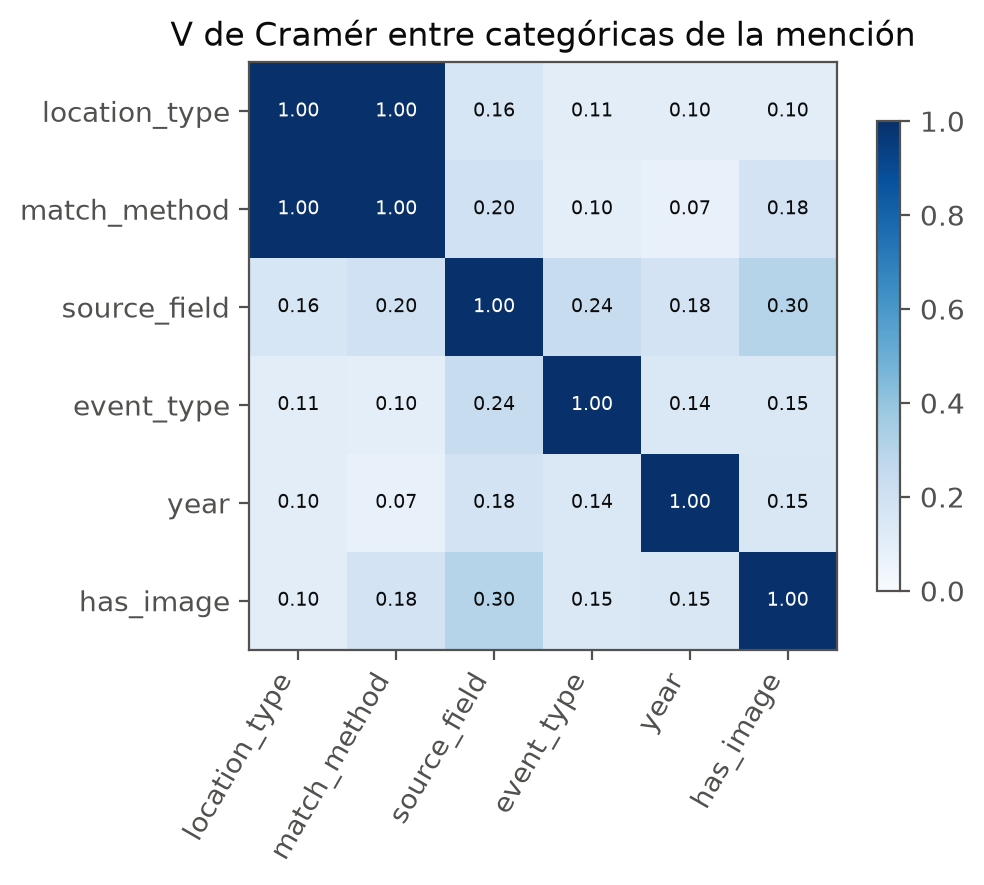

In [ ]:
_columns = ["location_type", "match_method", "source_field", "event_type", "year", "has_image"]
plot_heatmap(
    cramers_v_matrix(mentions.astype({column: str for column in _columns}), _columns),
    "V de Cramér entre categóricas de la mención",
    diverging=False,
)

In [ ]:
_points = mentions.merge(
    colonias[["colonia_id", "centroid_lat", "centroid_lon"]], on="colonia_id", how="left"
)
_points["point_lat"] = _points["lat"].fillna(_points["centroid_lat"])
_points["point_lon"] = _points["lon"].fillna(_points["centroid_lon"])
_points["center_lat"] = _points.groupby("post_id")["point_lat"].transform("mean")
_points["center_lon"] = _points.groupby("post_id")["point_lon"].transform("mean")
# Distancia equirrectangular en km al centro: basta a la escala de una ciudad.
_points["distance_to_center"] = np.hypot(
    (_points["point_lat"] - _points["center_lat"]) * 110.57,
    (_points["point_lon"] - _points["center_lon"])
    * 111.32
    * np.cos(np.radians(_points["center_lat"])),
)
_method = pd.get_dummies(_points["match_method"]).astype(float)
post_footprint = (
    _points.assign(
        share_catalog=_method["colonia_en_catalogo"],
        share_marker=_method["colonia_con_marcador"],
        share_cross=_method["cruce_geocodificado"],
        share_unmatched=_method["unmatched"],
        share_ocr=(_points["source_field"] == "ocr").astype(float),
    )
    .groupby("post_id")
    .agg(
        n_mentions=("raw_text", "size"),
        n_colonias=("colonia_id", "nunique"),
        share_catalog=("share_catalog", "mean"),
        share_marker=("share_marker", "mean"),
        share_cross=("share_cross", "mean"),
        share_unmatched=("share_unmatched", "mean"),
        share_ocr=("share_ocr", "mean"),
        spread_km=("distance_to_center", "mean"),
        center_lat=("center_lat", "first"),
        center_lon=("center_lon", "first"),
    )
    .join(posts.set_index("post_id"))
)
post_footprint["spread_km"] = post_footprint["spread_km"].fillna(0)
post_footprint.shape

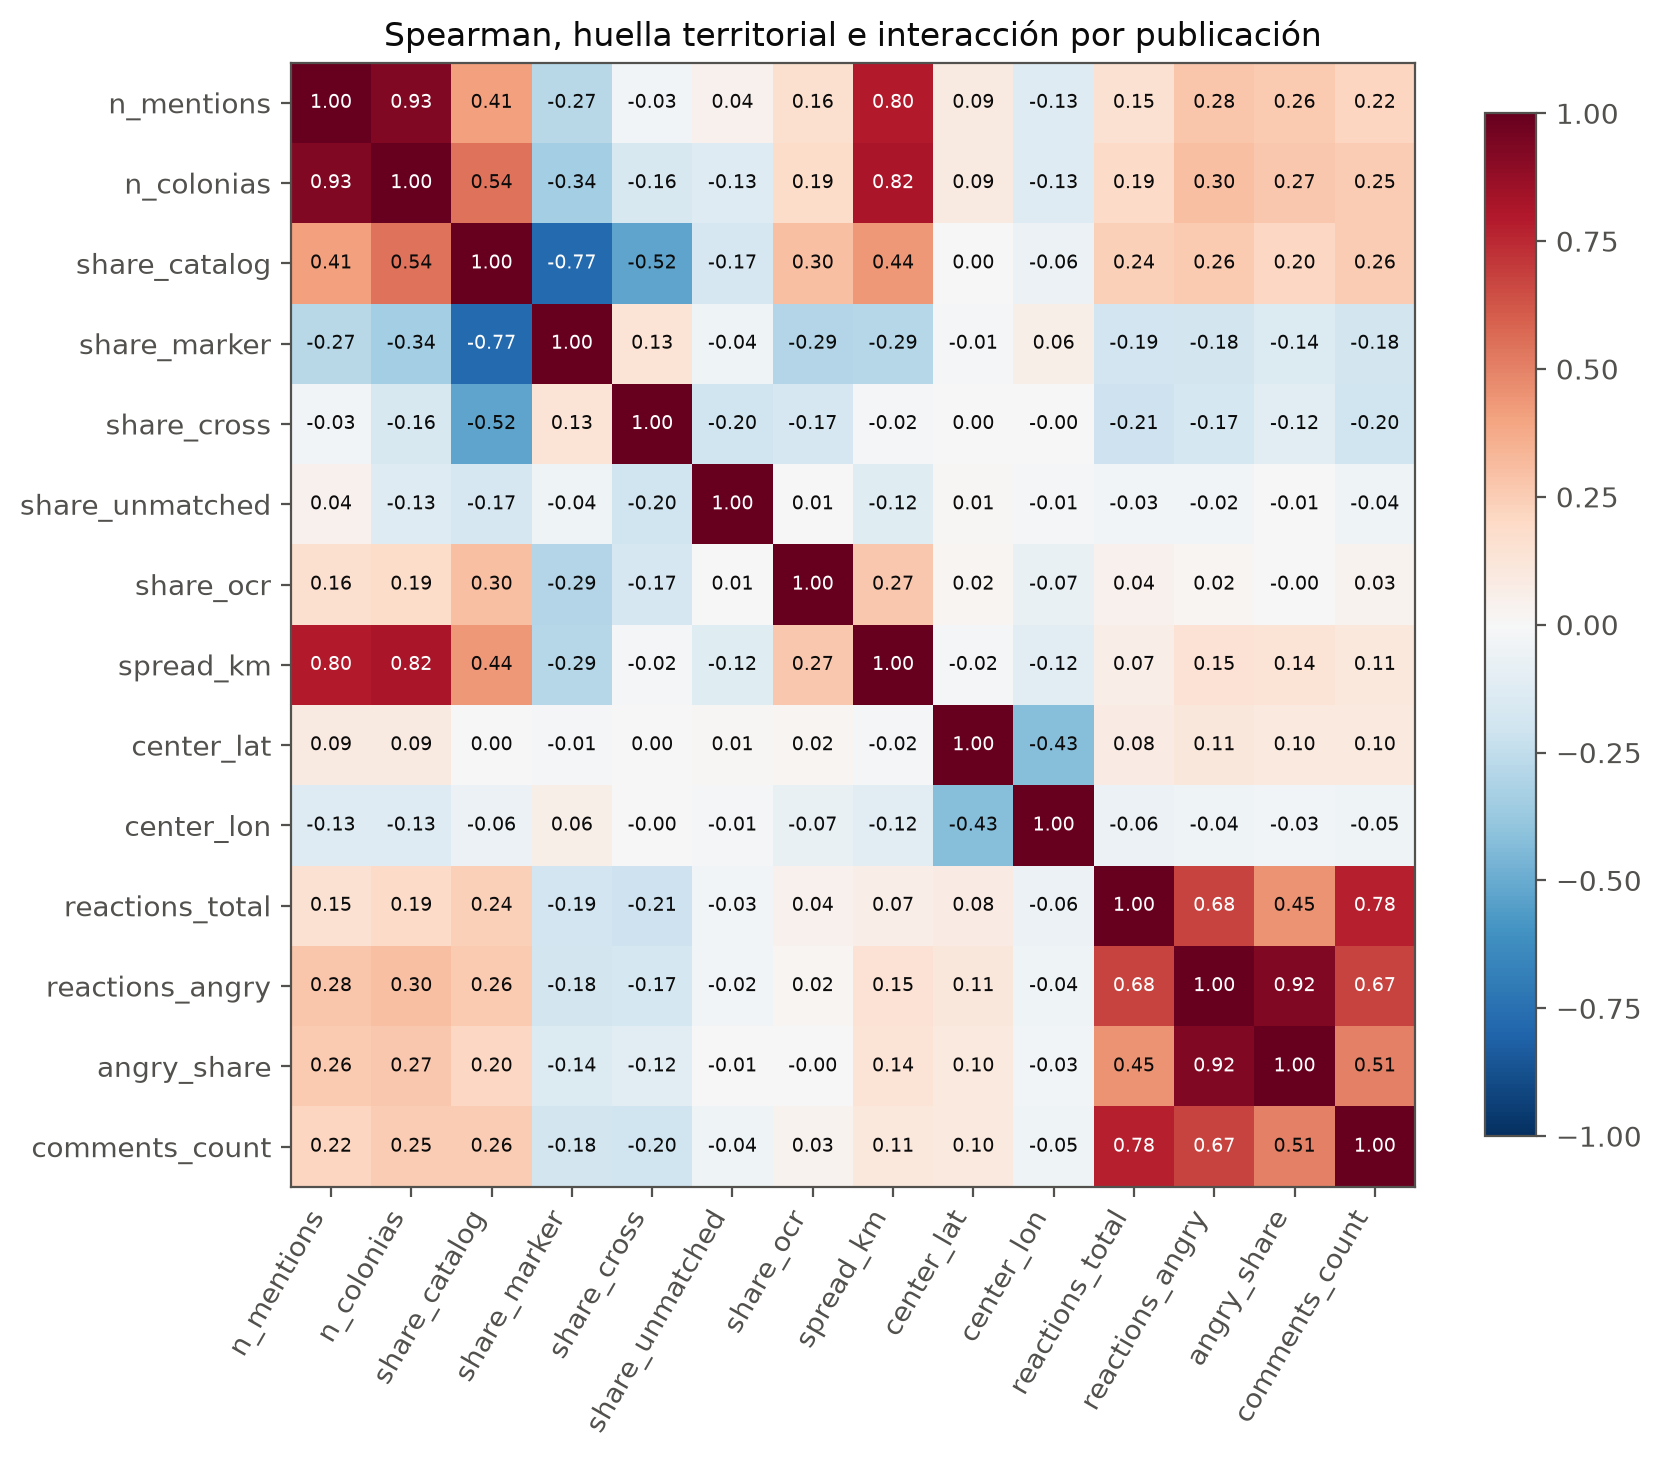

In [ ]:
footprint_numeric = [
    "n_mentions",
    "n_colonias",
    "share_catalog",
    "share_marker",
    "share_cross",
    "share_unmatched",
    "share_ocr",
    "spread_km",
    "center_lat",
    "center_lon",
    "reactions_total",
    "reactions_angry",
    "angry_share",
    "comments_count",
]
plot_heatmap(
    post_footprint[footprint_numeric].corr("spearman"),
    "Spearman, huella territorial e interacción por publicación",
)

- Entre categóricas, `location_type` y `match_method` son la misma información (V = 1:
  cada método pertenece a un solo tipo). El resto de asociaciones son débiles; la mayor
  es entre `source_field` y `has_image` (0.30), como era de esperar.
- `n_mentions`, `n_colonias` y `spread_km` van juntas (0.80 a 0.93): los avisos que
  nombran muchos lugares cubren zonas amplias. `share_ocr` se relaciona débilmente con
  ellas (0.16 a 0.27).
- `share_catalog` va en contra de `share_marker` (-0.77) y `share_cross` (-0.52): son
  proporciones que suman 1 junto con `share_unmatched`.
- La huella territorial se relaciona poco con la interacción: los avisos que nombran más
  colonias tienen algo más de enojo (0.27 a 0.30 con `angry_share` y `reactions_angry`) y
  casi el mismo total de reacciones (0.19). Afectar más colonias no garantiza más
  molestia.

## 6. Reducción de dimensión para visualización

Cada publicación con ubicaciones (3,788) se describe con su huella: `log1p` de
`n_mentions`, `n_colonias` y `spread_km`, las cinco proporciones y el centro (latitud y
longitud). Las publicaciones cuyas menciones no se resolvieron no tienen centro; se les
asigna el centro de la ciudad y se marca con `has_center`. Todo estandarizado.

In [ ]:
footprint_features = (
    np.log1p(post_footprint[["n_mentions", "n_colonias", "spread_km"]])
    .join(
        post_footprint[
            ["share_catalog", "share_marker", "share_cross", "share_unmatched", "share_ocr"]
        ]
    )
    .assign(
        has_center=post_footprint["center_lat"].notna().astype(int),
        center_lat=post_footprint["center_lat"].fillna(post_footprint["center_lat"].median()),
        center_lon=post_footprint["center_lon"].fillna(post_footprint["center_lon"].median()),
    )
)
footprint_matrix = StandardScaler().fit_transform(footprint_features)
footprint_matrix.shape

In [ ]:
_pca = PCA().fit(footprint_matrix)
print(
    "Varianza explicada acumulada:",
    _pca.explained_variance_ratio_.cumsum().round(2)[:5].tolist(),
)
pd.DataFrame(
    _pca.components_[:2].T, index=footprint_features.columns, columns=["PC1", "PC2"]
).round(2).sort_values("PC1")

Varianza explicada acumulada: [0.32, 0.49, 0.6, 0.69, 0.78]


,PC1,PC2
share_marker,-0.34,-0.23
share_cross,-0.21,-0.25
share_unmatched,-0.13,0.65
center_lon,-0.04,-0.01
center_lat,0.05,0.01
has_center,0.12,-0.65
share_ocr,0.22,0.16
spread_km,0.39,0.00
n_mentions,0.44,-0.00
share_catalog,0.44,0.09


In [ ]:
footprint_embeddings = embed_2d(footprint_matrix)

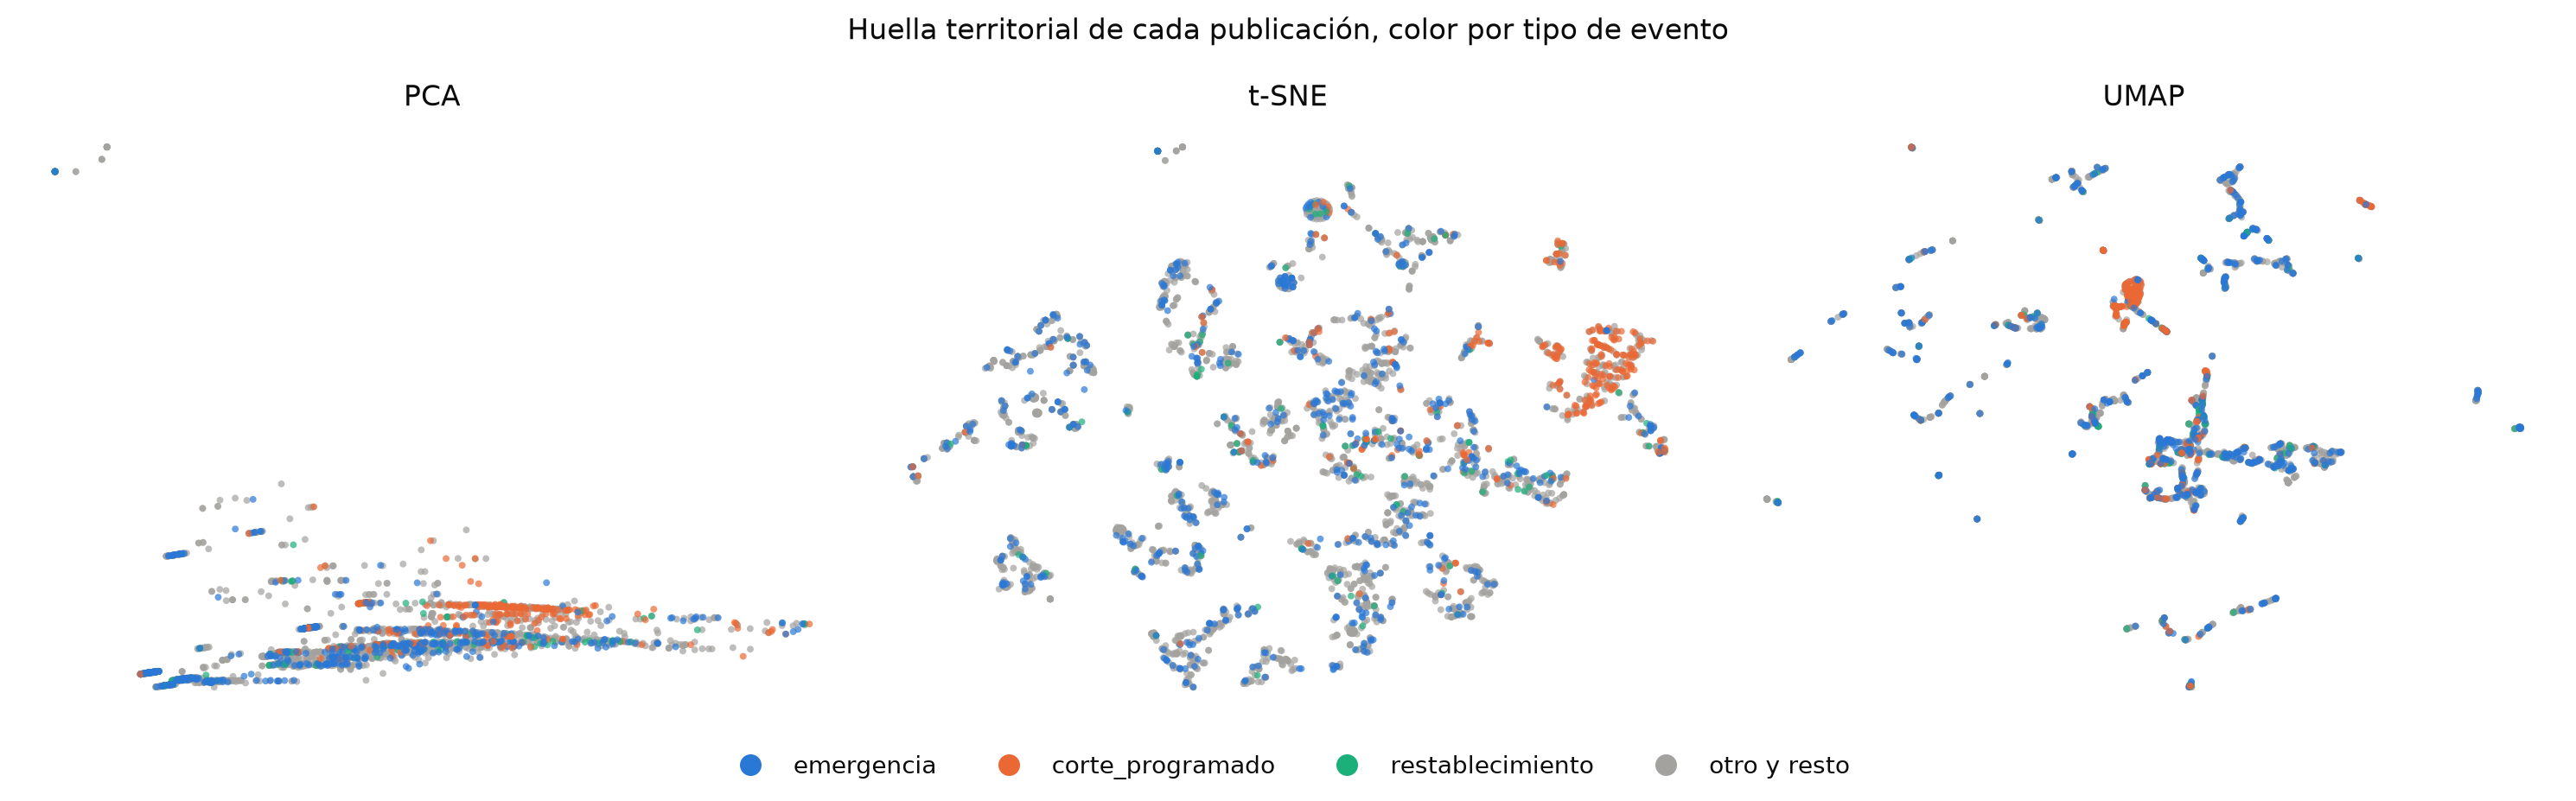

In [ ]:
plot_embeddings(
    footprint_embeddings,
    post_footprint["event_type"],
    "Huella territorial de cada publicación, color por tipo de evento",
)

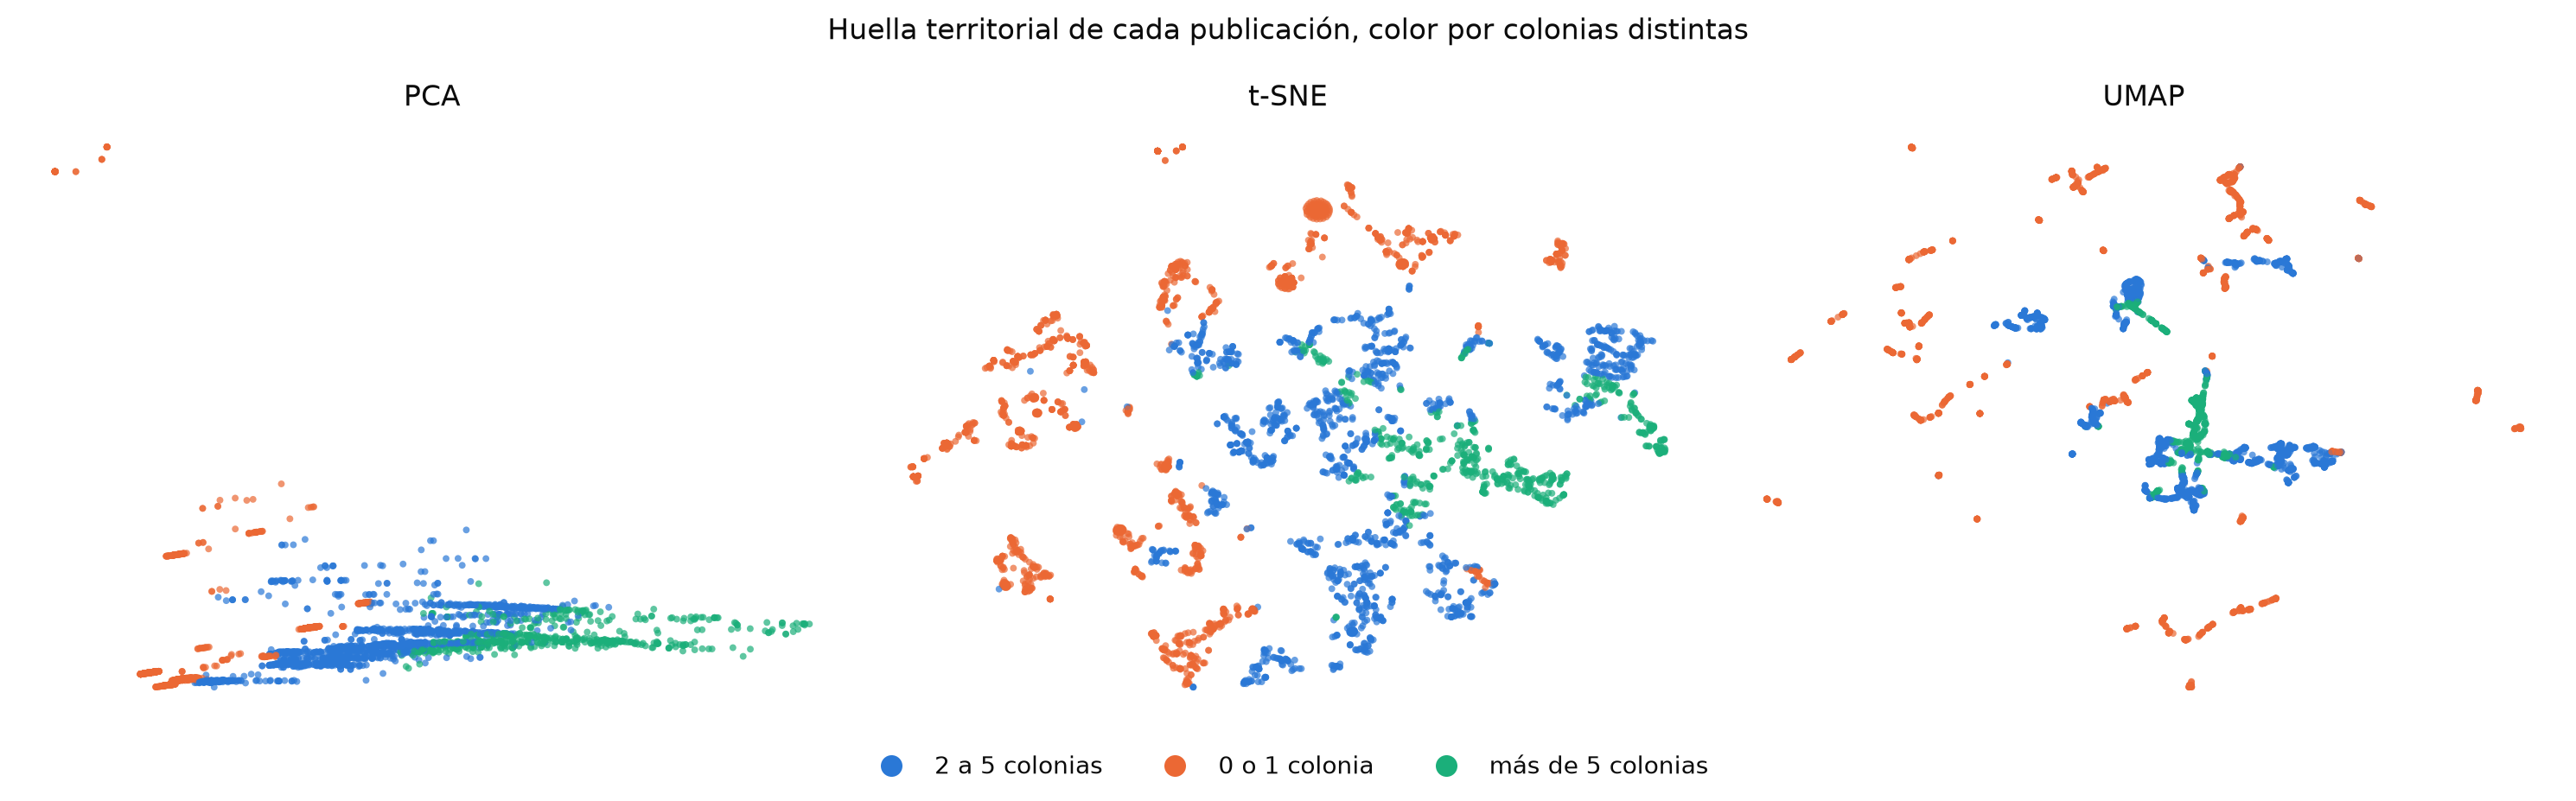

In [ ]:
_scope = pd.cut(
    post_footprint["n_colonias"],
    bins=[-np.inf, 1, 5, np.inf],
    labels=["0 o 1 colonia", "2 a 5 colonias", "más de 5 colonias"],
).astype(str)
plot_embeddings(
    footprint_embeddings,
    _scope,
    "Huella territorial de cada publicación, color por colonias distintas",
)

In [ ]:
embedding_quality(footprint_matrix, footprint_embeddings).to_frame()

,trustworthiness
PCA,0.951
t-SNE,0.999
UMAP,0.997


- PCA: las dos primeras componentes explican 49%. PC1 es el alcance (`n_colonias`,
  `n_mentions`, `share_catalog`, `spread_km`); PC2 separa las publicaciones cuyas
  menciones no se resolvieron (`share_unmatched` frente a `has_center`). Se ve como
  bandas paralelas, una por cada combinación discreta de proporciones.
- t-SNE y UMAP separan grupos que vienen de esas proporciones discretas: las
  publicaciones de un solo lugar (0 o 1 colonia) forman muchas islas pequeñas, una por
  método y zona; las de más de 5 colonias forman una región propia.
- El tipo de evento casi no forma grupos; la excepción es una isla de cortes programados
  con muchas colonias (los volantes). El alcance sí ordena las tres proyecciones.
- Trustworthiness: PCA 0.95, t-SNE 1.00, UMAP 1.00.

## 7. Consulta con los usuarios

| # | Hallazgo | Pregunta |
|---|---|---|
| 1 | 74% de las menciones son un nombre suelto de colonia (`colonia_en_catalogo`), el método menos seguro | ¿Aceptan estas menciones en el mapa, o prefieren ver solo las explícitas y los cruces, con menos cobertura pero más certeza? |
| 2 | Hay avisos que nombran hasta 91 lugares | ¿Un aviso masivo debe contar igual que uno de una calle en el conteo por colonia, o prefieren verlos como una capa aparte? |
| 3 | 21% de los cruces queda sin resolver por textos truncados | ¿Qué tan importante es ubicar cada cruce frente a ubicar la colonia? |
| 4 | Un cruce sobre un bulevar se asigna a la colonia más cercana y a veces cae en la de enfrente | Para un cruce sobre un bulevar, ¿quieren las dos colonias de ambos lados o una sola? |
| 5 | La extensión territorial de un aviso casi no se relaciona con su enojo | ¿Qué les dice más del impacto: cuántas colonias afecta un aviso, cuánto dura o cuánta molestia genera? |